1. Leer metadata.json
2. claves, tipos, cant reg
3. estad de los clips -> sino rompo todo 
4. anotaciones de las landamrks 
5. visualizacion 

In [1]:
#check env 
import sys 
print(sys.executable)

c:\Users\Angelina\miniforge3\envs\visper\python.exe


In [2]:
import pandas as pd
print(pd.__version__)
print(pd.__file__)

2.3.3
c:\Users\Angelina\miniforge3\envs\visper\lib\site-packages\pandas\__init__.py


In [3]:
import torch
import json
import os 
from pathlib import Path 
import pandas #trafico de animales 
import matplotlib
import matplotlib.pyplot as plt
import cv2

In [4]:
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("OpenCV:", cv2.__version__)

PyTorch: 2.6.0+cu126
CUDA disponible: True
OpenCV: 4.10.0


estructura y metadata check

In [5]:
import json
from pathlib import Path

DATA_DIR = Path(r"D:\ViSpeR\clips")
METADATA_PATH = DATA_DIR / "metadata.json"


with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata = json.load(f)

print(f"videos: {len(metadata)}")
print(f"tipo: {type(metadata).__name__}")

videos: 1283
tipo: dict


In [6]:
sample_id = next(iter(metadata))
sample = metadata[sample_id]

print("ID:", sample_id)
print("tipo:", type(sample))
print("campos:", sample.keys())

for key, value in sample.items():
    if isinstance(value, (list, tuple)):
        print(f"{key}: {type(value).__name__}, longitud={len(value)}")
    else:
        print(f"{key}: {value}")

ID: D:\ViSpeR\videos\0YEeb-WLF2w\00000.mp4
tipo: <class 'dict'>
campos: dict_keys(['label', 'length'])
label:  La ficción es una herramienta poderosa
length: 108


Distribucion del DS
basado en los 20 primeros videos

In [7]:
records = []

for path, item in metadata.items():
    records.append({
        "path": path,
        "label": item["label"].strip(),
        "frames": item["length"],
        "duration": item["length"] / 25,
        "text_length": len(item["label"].strip()),
        "word_count": len(item["label"].split())
    })

df = pd.DataFrame(records)

df.describe()

,frames,duration,text_length,word_count
count,1283.000000,1283.000000,1283.000000,1283.000000
mean,123.658613,4.946345,71.630553,12.986750
std,57.596128,2.303845,33.313746,6.086786
min,40.000000,1.600000,7.000000,2.000000
25%,82.000000,3.280000,47.000000,8.000000
50%,114.000000,4.560000,66.000000,12.000000
75%,154.000000,6.160000,90.000000,16.500000
max,626.000000,25.040000,290.000000,61.000000


Tenemos 1.135 clips, con una duración mediana de 4,48 segundos y 112 frames. La mayoría está entre 81 y 153 frames.

40 a 626 -> hay bastante GAP
esto implica: 
1. no puedo forzar a los clips a tener la misma cantidad de frames -> PADDING NOMA 
2. CTC era obvio T>= U depende de los tokens 

### 4: Comprobar Landmarks de ViSpeR
comprobar la consistencia y si puedo hacer bien el mapeo a los clips

In [8]:
ANNOTATIONS_DIR = Path(r"D:\ViSpeR\metadata_20")

metadata_annotations = {}

json_files = list(ANNOTATIONS_DIR.glob("*.json"))

for json_path in json_files:
    with open(json_path, "r", encoding="utf-8") as f:
        annotations = json.load(f)

    metadata_annotations.update(annotations)

print("Archivos JSON:", len(json_files))
print("Videos con anotaciones:", len(metadata_annotations))

video_id = next(iter(metadata_annotations))
segment = metadata_annotations[video_id][0]

print("\n--- SEGMENTO DE EJEMPLO ---")
print("Video ID:", video_id)
print("Campos:", segment.keys())

print("\n--- TIPOS ---")
print("Landmarks:", type(segment["landmarks"]))
print("Bounding boxes:", type(segment["bboxs"]))

print("\n--- CANTIDADES ---")
print("Landmarks:", len(segment["landmarks"]))
print("Bounding boxes:", len(segment["bboxs"]))

print("\n--- PRIMER ELEMENTO ---")
print("Landmark:", segment["landmarks"][0])
print("Bounding box:", segment["bboxs"][0])

Archivos JSON: 21
Videos con anotaciones: 21

--- SEGMENTO DE EJEMPLO ---
Video ID: 0YEeb-WLF2w
Campos: dict_keys(['start', 'end', 'label', 'landmarks', 'bboxs'])

--- TIPOS ---
Landmarks: <class 'list'>
Bounding boxes: <class 'list'>

--- CANTIDADES ---
Landmarks: 108
Bounding boxes: 108

--- PRIMER ELEMENTO ---
Landmark: [[0.366, 0.269], [0.425, 0.263], [0.39, 0.324], [0.37, 0.367], [0.415, 0.363]]
Bounding box: [0.328, 0.164, 0.468, 0.437]


20 json 20 anotaciones : gud  
Las landmark tiene 5 pares   
las bb tienen xmin,ymin, xmax, ymax : gustav like , estan normalizadas entre 0 y 1parece

In [9]:
import numpy as np

annotation_records = []

for video_id, segments in metadata_annotations.items():
    for i, segment in enumerate(segments):
        landmarks = segment["landmarks"]
        bboxs = segment["bboxs"]

        annotation_records.append({
            "video_id": video_id,
            "segment": i,
            "frames_landmarks": len(landmarks),
            "frames_bboxs": len(bboxs),
            "label": segment["label"],
            "landmarks_per_frame": [
                len(frame) for frame in landmarks
            ],
            "bbox_values_per_frame": [
                len(box) for box in bboxs
            ]
        })

annotations_df = pd.DataFrame(annotation_records)

print("Total de segmentos:", len(annotations_df))
print("\n--- DISTRIBUCIÓN ---")
print(annotations_df[["frames_landmarks", "frames_bboxs"]].describe())

print("\n--- INCONSISTENCIAS ---")
print(
    "Landmarks y bboxs con distinta cantidad de frames:",
    (annotations_df["frames_landmarks"] != annotations_df["frames_bboxs"]).sum()
)

print(
    "Frames con distinta cantidad de 5 landmarks:",
    sum(
        any(n != 5 for n in frames)
        for frames in annotations_df["landmarks_per_frame"]
    )
)

print(
    "Frames con bboxs distintos de 4 valores:",
    sum(
        any(n != 4 for n in frames)
        for frames in annotations_df["bbox_values_per_frame"]
    )
)

Total de segmentos: 1196

--- DISTRIBUCIÓN ---
       frames_landmarks  frames_bboxs
count       1196.000000   1196.000000
mean         123.532609    123.532609
std           58.330524     58.330524
min           40.000000     40.000000
25%           81.000000     81.000000
50%          113.000000    113.000000
75%          154.000000    154.000000
max          626.000000    626.000000

--- INCONSISTENCIAS ---
Landmarks y bboxs con distinta cantidad de frames: 0
Frames con distinta cantidad de 5 landmarks: 0
Frames con bboxs distintos de 4 valores: 0


mira que calidad

#### Rango de Coordenadas

In [10]:
landmark_values = []
bbox_values = []

for segments in metadata_annotations.values():
    for segment in segments:
        for frame in segment["landmarks"]:
            landmark_values.extend(frame)

        for box in segment["bboxs"]:
            bbox_values.extend(box)

landmark_values = np.array(landmark_values)
bbox_values = np.array(bbox_values)

print("--- LANDMARKS ---")
print("Mínimo:", landmark_values.min())
print("Máximo:", landmark_values.max())

print("\n--- BOUNDING BOXES ---")
print("Mínimo:", bbox_values.min())
print("Máximo:", bbox_values.max())

--- LANDMARKS ---
Mínimo: 0.054
Máximo: 0.938

--- BOUNDING BOXES ---
Mínimo: 0.005
Máximo: 0.952


yes -> 0,1


Que es lo que esta mostrando Visper? lo estoy levantando bien? Lets see

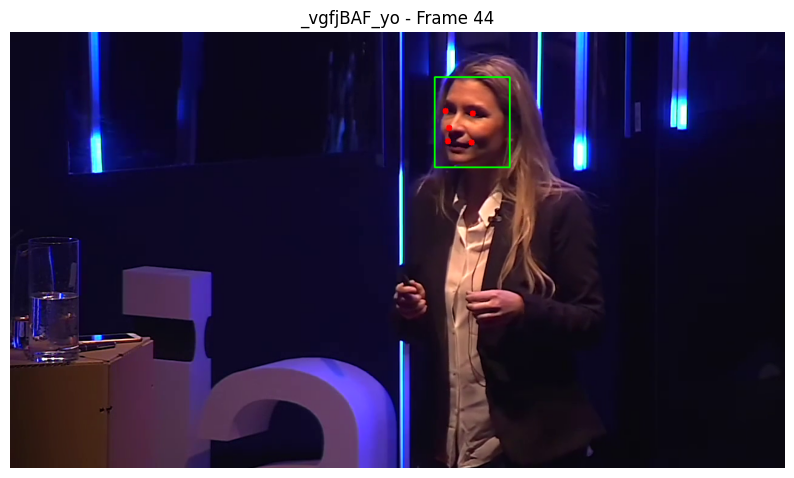

In [13]:
# Seleccionar el frame central del segmento
frame_idx = len(segment["landmarks"]) // 2

# Obtener las anotaciones
landmarks = np.array(segment["landmarks"][frame_idx])
bbox = segment["bboxs"][frame_idx]

# Cargar video original
video_path = DATA_DIR.parent / "videos" / f"{video_id}.mp4"

cap = cv2.VideoCapture(str(video_path))
cap.set(cv2.CAP_PROP_POS_FRAMES, int(segment["start"] * 25) + frame_idx)

ret, frame = cap.read()
cap.release()

if not ret:
    print("No se pudo leer el frame")
else:
    h, w = frame.shape[:2]

    # Convertir coordenadas normalizadas a píxeles
    points = (landmarks * [w, h]).astype(int)
    x1, y1, x2, y2 = (np.array(bbox) * [w, h, w, h]).astype(int)

    # Dibujar bounding box
    cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)

    # Dibujar landmarks
    for x, y in points:
        cv2.circle(frame, (x, y), 5, (0, 0, 255), -1)

    # Mostrar
    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(f"{video_id} - Frame {frame_idx}")
    plt.show()

nods
### Conclusiones  
1. conversion normalizada ok 
2. landmarks ok 
3. bbs ubicadas bien 
4. ref temporal de segmentos ok 

levantamos bien el dataset 